## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'outputSVMAntiBurnoutPolynomial'
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data: {len(df)}')

Jumlah data: 50000


### 1.2 Identifikasi Kolom yang Digunakan

In [3]:
numeric_columns = df.select_dtypes(
    include='number'
).columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal:'
)
print(
    categorical_columns.tolist()
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal:
['Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level', 'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


## 2. Preprocessing

### 2.1 Seleksi Kolom

In [4]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,58.0,2786.0,67,3.0,7.0,4.6,74.0,75.0,26.0,18,...,Poor,High,Weekly,Yes,Yes,No,Yes,No,Yes,Average
1,24.0,8027.0,44,5.0,8.0,4.7,58.0,80.0,29.0,37,...,Poor,Moderate,Weekly,Yes,Yes,Yes,No,Yes,No,Good
2,59.0,3177.0,60,8.0,7.0,6.3,54.0,55.0,44.0,48,...,Average,Moderate,Daily,Yes,No,No,No,Yes,No,Average
3,65.0,4093.0,25,2.0,9.0,7.1,12.0,11.0,88.0,80,...,Good,Low,Weekly,Yes,No,No,No,No,Yes,Good
4,64.0,NaN,52,1.0,4.0,9.1,25.0,48.0,67.0,76,...,Excellent,Low,Never,Yes,No,No,No,Yes,No,Poor


### 2.2 Encoding Data Kategorikal

In [5]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    }
}

for column, mapping in encoding_maps.items():

    X[column] = (
        X[column]
        .map(mapping)
    )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,1,3,2,1,1,1,1,1,0,0.0,2
1,1,3,1,1,1,1,0,0,1,1.0,1
2,0,2,1,0,1,0,1,0,1,1.0,2
3,2,1,0,1,1,0,1,0,0,0.0,1
4,0,0,0,3,1,0,1,0,1,1.0,3


### 2.3 Pemeriksaan Missing Values


In [6]:
print('Missing value sebelum preprocessing:')
print(X.isnull().sum())


Missing value sebelum preprocessing:
Age                               250
Monthly_Income_USD               1450
Work_Hours_Per_Week                 0
Job_Satisfaction                  500
Work_Life_Balance                 650
Sleep_Hours                       950
Anxiety_Score                     800
Depression_Score                  850
Mood_Score                        900
Emotional_Stability                 0
Physical_Activity_Hours          1100
Meditation_Minutes               1200
Screen_Time_Hours                 850
Social_Media_Hours                600
Gaming_Hours                      750
Coffee_Cups_Per_Day                 0
Life_Satisfaction                 700
Productivity_Score                950
Absenteeism_Days                    0
Remote_Work                         0
Sleep_Quality                       0
Stress_Level                        0
Exercise_Frequency                  0
Alcohol_Consumption                 0
Smoking                             0
Healthy_Diet 

### 2.4 Pembagian Data Latih dan Uji (80:20, stratified)

Data dibagi **sebelum** imputasi dan standardisasi untuk mencegah kebocoran informasi (*data leakage*).


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Dimensi X_train:', X_train.shape)
print('Dimensi X_test :', X_test.shape)


Dimensi X_train: (40000, 30)
Dimensi X_test : (10000, 30)


### 2.5 Penanganan Missing Values dan Standardisasi

Imputasi dan standardisasi hanya di-fit pada data latih, lalu diterapkan ke data uji agar tidak ada kebocoran informasi (*data leakage*).


In [8]:
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()

X_train = pd.DataFrame(
    scaler.fit_transform(imputer.fit_transform(X_train)),
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    scaler.transform(imputer.transform(X_test)),
    columns=X.columns,
    index=X_test.index
)

X_train.head()


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
18794,1.555718,1.169947,-1.214848,-1.576378,-1.579896,-1.396609,-1.567375,-1.172177,1.580243,1.556101,...,1.593926,-1.012223,-1.349580,1.009142,1.002603,-1.004360,-0.393236,1.006974,-1.011543,-1.345729
18922,0.327757,-0.352506,-1.622237,-0.172846,-0.878016,-1.046550,-0.636677,-1.556041,1.188571,0.405605,...,0.546823,-1.012223,-0.453935,1.009142,-0.997403,0.995659,-0.393236,1.006974,0.996662,0.445174
13028,-0.683504,-0.793965,0.278912,-0.172846,0.876683,-0.871521,-0.675456,0.209736,0.091889,0.405605,...,0.546823,-1.012223,1.337355,-0.990941,-0.997403,0.995659,-0.393236,-0.993074,-1.011543,-1.345729
17779,1.266786,0.872069,1.568978,1.230686,1.227623,-0.813178,1.379836,0.631987,-0.887291,-1.128391,...,0.546823,0.415504,0.441710,-0.990941,-0.997403,-1.004360,-0.393236,-0.993074,-1.011543,0.445174
8978,0.977854,0.231923,1.297385,1.230686,0.000000,-0.813178,1.573731,1.860354,-2.179808,-1.741989,...,0.546823,1.843232,0.441710,1.009142,1.002603,-1.004360,2.543003,1.006974,-1.011543,-0.450278


### 2.6 Data Bersih

In [9]:
print('Dimensi data fitur (X)            :', X.shape)
print('Dimensi data latih (X_train)      :', X_train.shape)
print('Dimensi data uji (X_test)         :', X_test.shape)
print('Missing value data latih (setelah):', X_train.isnull().sum().sum())
print('Missing value data uji (setelah)  :', X_test.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts().sort_index())


Dimensi data fitur (X)            : (50000, 30)
Dimensi data latih (X_train)      : (40000, 30)
Dimensi data uji (X_test)         : (10000, 30)
Missing value data latih (setelah): 0
Missing value data uji (setelah)  : 0

Distribusi kelas target (y):
Burnout_Risk
0    25369
1    14780
2     9851
Name: count, dtype: int64


## 3. Modeling

### 3.1 Inisialisasi Model SVM Polynomial

In [10]:
model = SVC(
    kernel='poly',
    degree=3,
    C=1.0,
    random_state=42
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [11]:
tracemalloc.start()
start_time = time.process_time()

model.fit(
    X_train,
    y_train
)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 82.5000 detik
Penggunaan Memori Peak: 18.7033 MB


### 3.3 Prediksi Data Uji

In [12]:
y_pred = model.predict(
    X_test
)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

df_prediksi.head()

,Actual,Predicted
15522,2,2
35306,0,0
90,1,1
48756,0,0
19181,0,0


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [13]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.9115    0.8605    0.8852      5074
Moderate (1)     0.6489    0.7733    0.7057      2956
    High (2)     0.8542    0.7315    0.7881      1970

    accuracy                         0.8093     10000
   macro avg     0.8048    0.7884    0.7930     10000
weighted avg     0.8226    0.8093    0.8130     10000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[4366  708    0]
 [ 424 2286  246]
 [   0  529 1441]]


### 4.3 Metrik Evaluasi Data Uji

In [15]:
acc = accuracy_score(
    y_test,
    y_pred
)

prec_macro = precision_score(
    y_test,
    y_pred,
    average='macro'
)

rec_macro = recall_score(
    y_test,
    y_pred,
    average='macro'
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average='macro'
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.8093
Precision (Macro)  : 0.8048
Recall (Macro)     : 0.7884
F1-Score (Macro)   : 0.7930
F1-Score (Weighted): 0.8130


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [16]:
cv_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('model', model)
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_results = cross_validate(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv


,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.80810,0.801897,0.785671,0.790483,0.811533
1,Fold 2,0.80890,0.803267,0.786422,0.791921,0.811944
2,Fold 3,0.80370,0.797736,0.777792,0.784279,0.806715
3,Fold 4,0.80590,0.803049,0.780838,0.787586,0.809275
4,Fold 5,0.80940,0.805615,0.784700,0.791281,0.812519
Mean,NaN,0.80720,0.802313,0.783085,0.789110,0.810397
Std,NaN,0.00212,0.002588,0.003271,0.002834,0.002145


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [17]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'SVM Polynomial',
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

df_runtime

,Model,Training_Time_Seconds,Peak_Memory_MB
0,SVM Polynomial,82.5,18.7033


### 4.6 Ringkasan Evaluasi Model

In [18]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['SVM Polynomial'],
        'Kernel': ['Polynomial'],
        'C': [1.0],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

evaluation_result

,Model,Kernel,C,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,SVM Polynomial,Polynomial,1.0,0.8093,0.8048,0.7884,0.793,0.813,0.8072,0.7891,82.5,18.7033


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

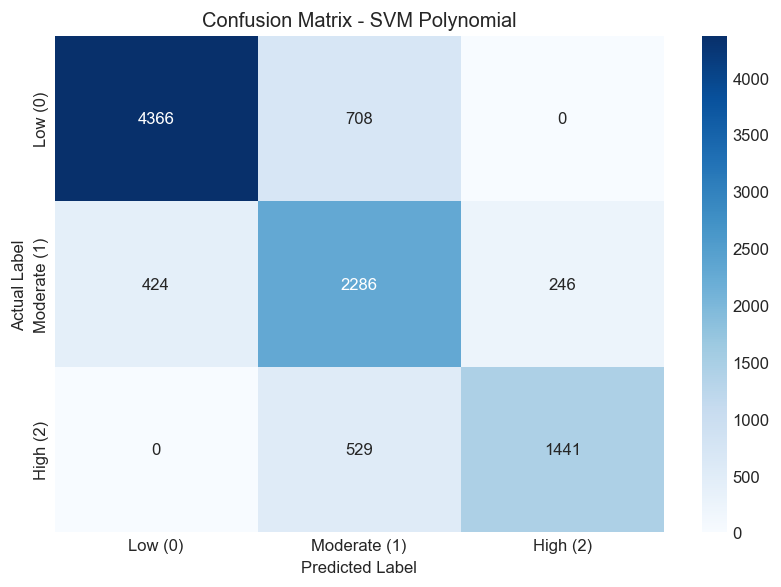

In [19]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title('Confusion Matrix - SVM Polynomial')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/confusion_matrix_polynomial.png'
)
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

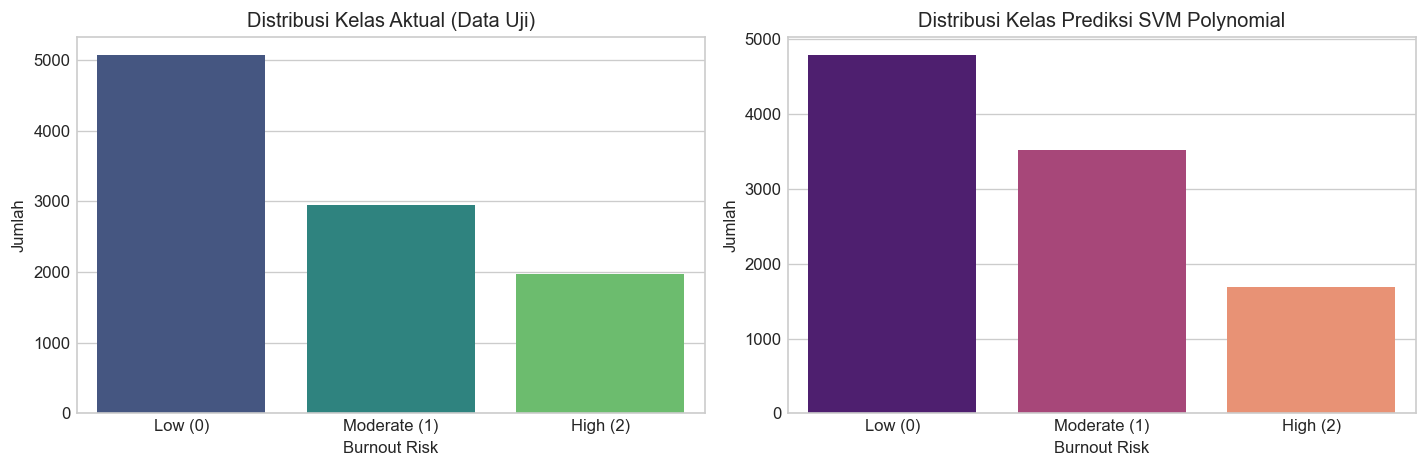

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    x=y_test,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Distribusi Kelas Aktual (Data Uji)')
axes[0].set_xticklabels(target_names)
axes[0].set_xlabel('Burnout Risk')
axes[0].set_ylabel('Jumlah')

sns.countplot(
    x=y_pred,
    ax=axes[1],
    palette='magma'
)
axes[1].set_title('Distribusi Kelas Prediksi SVM Polynomial')
axes[1].set_xticklabels(target_names)
axes[1].set_xlabel('Burnout Risk')
axes[1].set_ylabel('Jumlah')

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/distribution_actual_vs_predicted_polynomial.png'
)
plt.show()

### 5.3 Visualisasi Metrik Evaluasi Stratified 5-Fold Cross-Validation

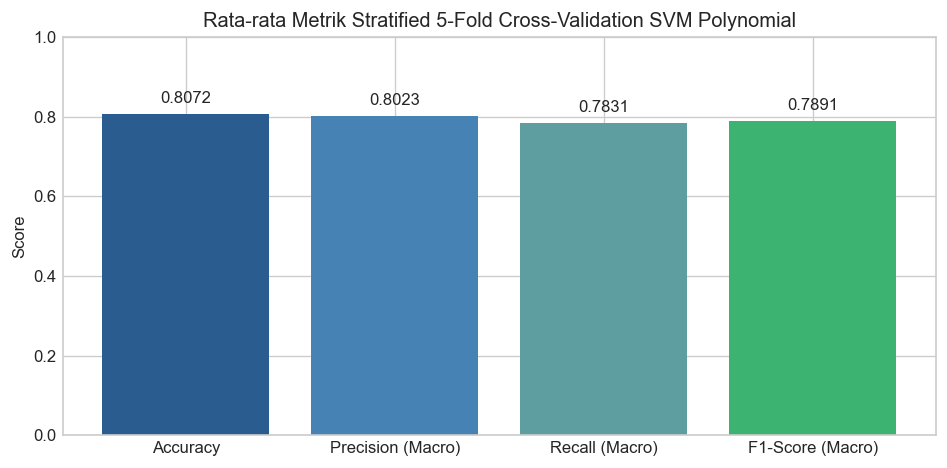

In [21]:
metrics_cv = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
cv_means = [
    cv_results['test_accuracy'].mean(),
    cv_results['test_precision_macro'].mean(),
    cv_results['test_recall_macro'].mean(),
    cv_results['test_f1_macro'].mean()
]

plt.figure(figsize=(8, 4))
bars = plt.bar(
    metrics_cv,
    cv_means,
    color=['#2b5c8f', '#4682b4', '#5f9ea0', '#3cb371']
)
plt.title('Rata-rata Metrik Stratified 5-Fold Cross-Validation SVM Polynomial')
plt.ylabel('Score')
plt.ylim(0, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.02,
        f'{yval:.4f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/cv_metrics_polynomial.png'
)
plt.show()

## 6. Analisis

### 6.1 Analisis Jumlah Support Vectors per Kelas

In [22]:
df_support = pd.DataFrame(
    {
        'Kelas': target_names,
        'Jumlah_Support_Vectors': model.n_support_
    }
)

total_sv = sum(model.n_support_)
total_train = len(X_train)
print(f'Total Support Vectors: {total_sv} dari {total_train} sampel latih ({total_sv / total_train * 100:.2f}%)')
df_support

Total Support Vectors: 17536 dari 40000 sampel latih (43.84%)


,Kelas,Jumlah_Support_Vectors
0,Low (0),5268
1,Moderate (1),8832
2,High (2),3436


### 6.2 Visualisasi Distribusi Support Vectors per Kelas (Polynomial)

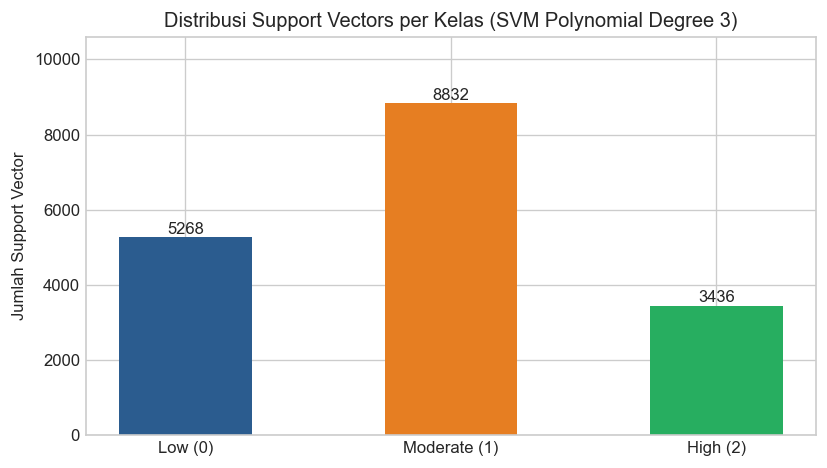

In [23]:
plt.figure(figsize=(7, 4))
bars = plt.bar(
    target_names,
    model.n_support_,
    color=['#2b5c8f', '#e67e22', '#27ae60'],
    width=0.5
)
plt.title('Distribusi Support Vectors per Kelas (SVM Polynomial Degree 3)')
plt.ylabel('Jumlah Support Vector')
plt.ylim(0, max(model.n_support_) * 1.2)

for bar in bars:
    yval = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 15,
        f'{yval}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.savefig(
    f'{OUTPUT_DIR}/support_vectors_polynomial.png'
)
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [24]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_svm_polynomial.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [25]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_svm_polynomial.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [26]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_svm_polynomial.csv'
)